In [104]:
# 1.1.3
# полином 1-го порядка по данным с kaggle
# https://www.kaggle.com/datasets/andonians/random-linear-regression

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv("regression.csv")
data = data.drop([213])

x = np.array(data.x)
y = np.array(data.y)

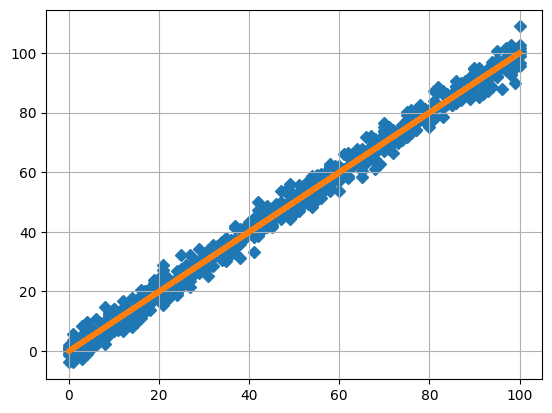

In [107]:
m = np.vstack([x, np.ones(len(x))]).T

s = np.linalg.lstsq(m, y, rcond = None)[0]

plt.plot(x, y, "D", zorder = 0)

plt.plot(x, s[0] * x + s[1], "-", lw = 4, zorder = 5)
plt.grid()
plt.show()

In [108]:
# полином 2-го порядка по случайным данным

delta = 1.0

x = np.linspace(-10, 10, 20)
y = x ** 2 + delta * (np.random.rand(20) - 0.5)
x += delta * (np.random.rand(20) - 0.5)

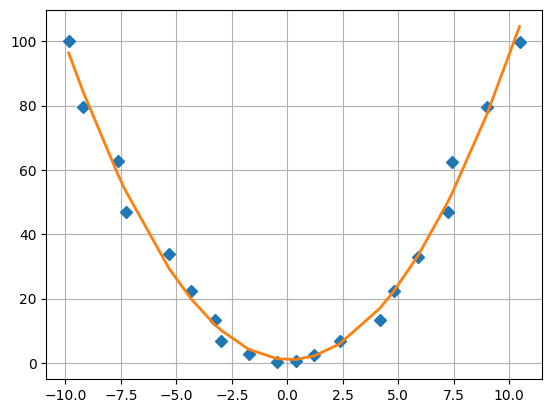

In [109]:
m = np.vstack((x ** 2, x, np.ones(20))).T

s = np.linalg.lstsq(m, y, rcond = None)[0]

plt.plot(x, y, "D")

plt.plot(x, s[0] * x ** 2 + s[1] * x + s[2], "-", lw = 2)
plt.grid()
plt.show()

In [110]:
# полином 3-го порядка по случайным данным

delta = 1.0

x = np.linspace(-10, 10, 20)
y = x ** 3 + delta * (np.random.rand(20) - 0.5)
x += delta * (np.random.rand(20) - 0.5)

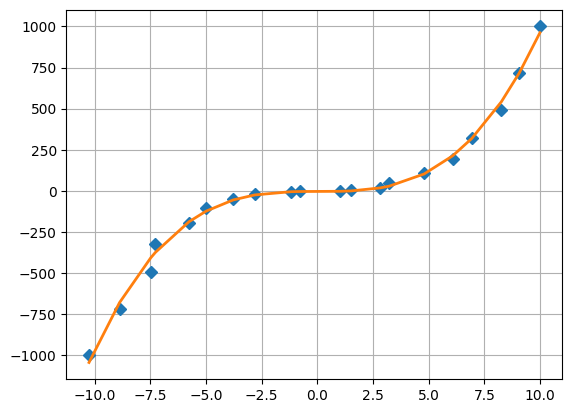

In [111]:
m = np.vstack((x ** 3, x ** 2, x, np.ones(20))).T

s = np.linalg.lstsq(m, y, rcond = None)[0]

plt.plot(x, y, "D")

plt.plot(x, s[0] * x ** 3 + s[1] * x ** 2 + s[2] * x + s[3], "-", lw = 2)
plt.grid()
plt.show()

In [112]:
# проверяем как данные ложатся на кривую
# 1

from scipy.optimize import curve_fit

beta = (0.25, 0.75)

def f(x, b0, b1):
    return b0 + b1 * x

xdata = np.linspace(-20, 20, 100)

y = f(xdata, *beta)

ydata = y + 0.1 * np.random.rand(len(xdata))
beta_opt, beta_cov = curve_fit(f, xdata, ydata)

lin_dev = sum(beta_cov[0])

residuals = ydata - f(xdata, *beta_opt)
fres = sum(residuals ** 2)

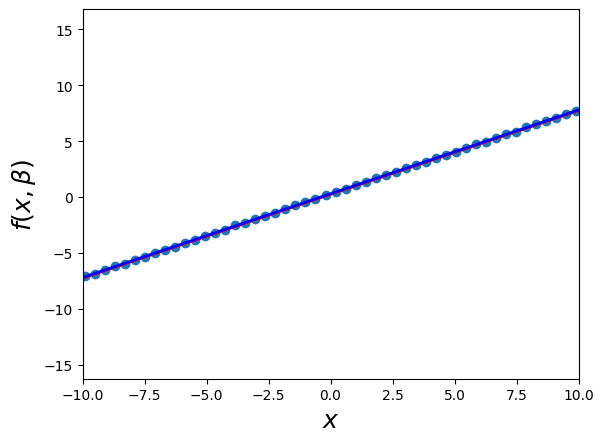

In [115]:
fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, "r", lw = 2)
ax.plot(xdata, f(xdata, *beta_opt), "b", lw = 2)
ax.set_xlim(-10, 10)
ax.set_xlabel(r"$x$", fontsize = 18)
ax.set_ylabel(r"$f(x, \beta)$", fontsize = 18)
plt.show()

In [117]:
# 2

beta = (0.25, 0.75, 0.5)

def f(x, b0, b1, b2):
    return b0 + b1 * x + b2 * x * x

xdata = np.linspace(-10, 10, 100)

y = f(xdata, *beta)

ydata = y + 0.1 * np.random.randn(len(xdata))
beta_opt, beta_cov = curve_fit(f, xdata, ydata)

line_dev = sum(beta_cov[0])

residuals = ydata - f(xdata, *beta_opt)
fres = sum(residuals ** 2)

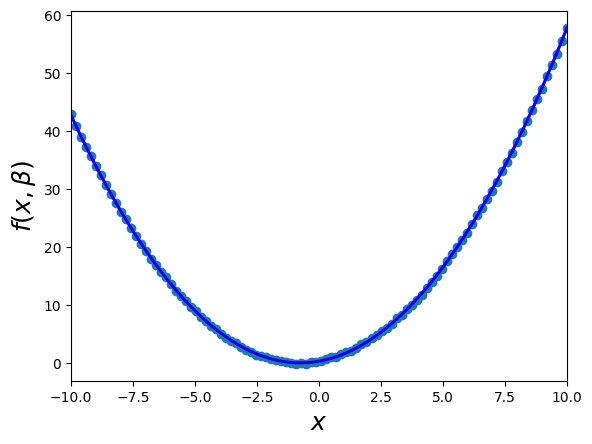

In [118]:
fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, "r", lw = 2)
ax.plot(xdata, f(xdata, *beta_opt), "b", lw = 2)
ax.set_xlim(-10, 10)
ax.set_xlabel(r"$x$", fontsize = 18)
ax.set_ylabel(r"$f(x, \beta)$", fontsize = 18)
plt.show()

In [124]:
# 3

beta = (1, 2)

def f(x, b0, b1):
    return b0 + b1 * np.log(x)

xdata = np.linspace(1, 20, 50)

y = f(xdata, *beta)

ydata = y + 0.1 * np.random.rand(len(xdata))
beta_opt, beta_cov = curve_fit(f, xdata, ydata)

line_dev = sum(beta_cov[0])

residuals = ydata - f(xdata, *beta_opt)
fres = sum(residuals ** 2)

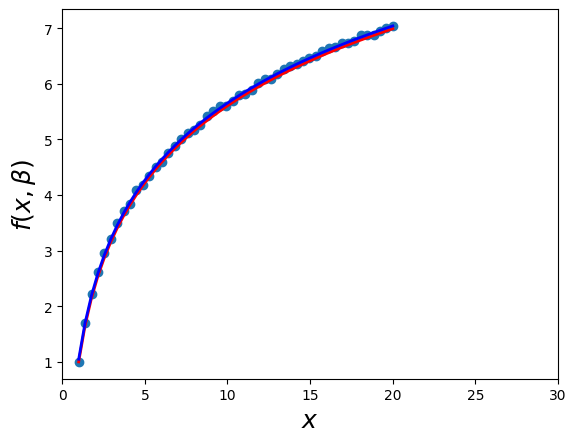

In [125]:
fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, "r", lw = 2)
ax.plot(xdata, f(xdata, *beta_opt), "b", lw = 2)
ax.set_xlim(0, 30)
ax.set_xlabel(r"$x$", fontsize = 18)
ax.set_ylabel(r"$f(x, \beta)$", fontsize = 18)
plt.show()

In [128]:
# 4

beta = (1, 2)

def f(x, b0, b1):
    return b0 * x ** b1

xdata = np.linspace(0.01, 100, 20)
y = f(xdata, *beta)

ydata = y + 0.1 * np.random.rand(len(xdata))
beta_opt, beta_cov = curve_fit(f, xdata, ydata)

line_dev = sum(beta_cov[0])

residuals = ydata - f(xdata, *beta_opt)
fres = sum(residuals ** 2)

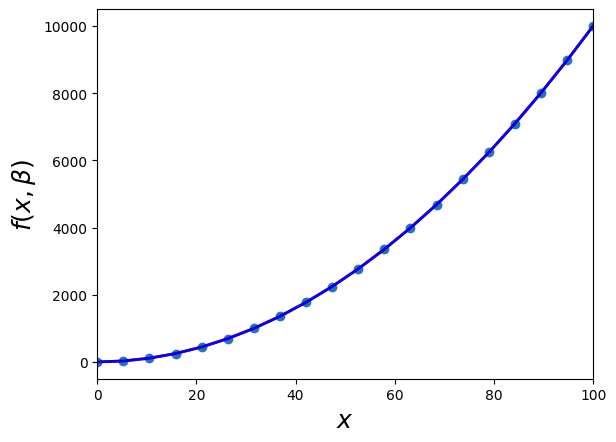

In [129]:
fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, "r", lw = 2)
ax.plot(xdata, f(xdata, *beta_opt), "b", lw = 2)
ax.set_xlim(0, 100)
ax.set_xlabel(r"$x$", fontsize = 18)
ax.set_ylabel(r"$f(x, \beta)$", fontsize = 18)
plt.show()

In [133]:
# 1.2 Задание

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

data = pd.read_csv("regression.csv")
data = data.drop([213])

In [134]:
X = data.iloc[:, :-1].values
y = data.iloc[:, 1].values

In [135]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [136]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [137]:
regressor.coef_

array([0.99831656])

In [138]:
y_pred = regressor.predict(X_test)

df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
df

,Actual,Predicted
0,29.667360,28.979528
1,56.687188,57.930708
2,85.027790,83.886939
3,73.138500,75.900406
4,48.437538,53.937442
...,...,...
135,14.002263,16.001413
136,94.151492,96.865054
137,40.831821,42.955960
138,19.471008,18.996362


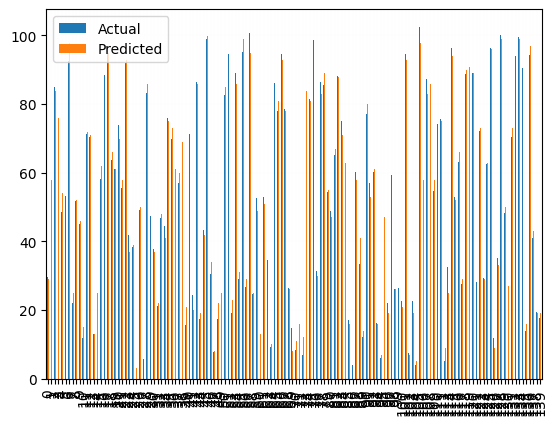

In [140]:
df.plot(kind = "bar")
plt.grid(which = "major", linestyle = "-",
        linewidth = "0.01", color = "green")
plt.grid(which = "major", linestyle = ":",
        linewidth = "0.01", color = "black")
plt.show()

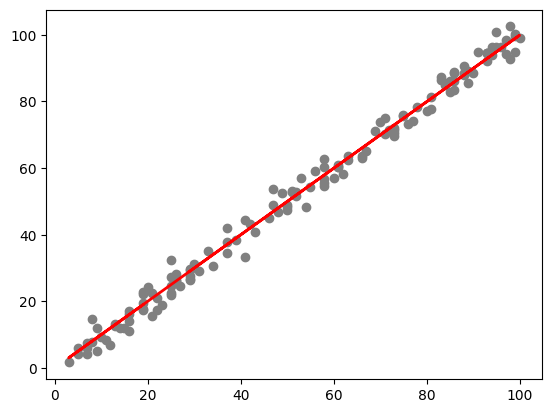

In [141]:
plt.scatter(X_test, y_test, color = "gray")
plt.plot(X_test, y_pred, color = "red", linewidth = 2)
plt.show()

In [142]:
# Множественная регрессия

from sklearn import metrics

url = "https://raw.githubusercontent.com/likarajo/petrol_consumption/master/data/petrol_consumption.csv"

df = pd.read_csv(url)

df.head()

,Petrol_tax,Average_income,Paved_Highways,Population_Driver_licence(%),Petrol_Consumption
0,9.0,3571,1976,0.525,541
1,9.0,4092,1250,0.572,524
2,9.0,3865,1586,0.580,561
3,7.5,4870,2351,0.529,414
4,8.0,4399,431,0.544,410


In [146]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [147]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2,
                                                   random_state = 0)

regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [148]:
coeff_df = pd.DataFrame(regressor.coef_, X.columns, columns = ["Coefficient"])
coeff_df

,Coefficient
Petrol_tax,-40.016660
Average_income,-0.065413
Paved_Highways,-0.004741
Population_Driver_licence(%),1341.862121


In [149]:
y_pred = regressor.predict(X_test)
df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
df

,Actual,Predicted
29,534,469.391989
4,410,545.645464
26,577,589.668394
30,571,569.730413
32,577,649.774809
37,704,646.631164
34,487,511.608148
40,587,672.475177
7,467,502.074782
10,580,501.270734


In [153]:
f"Mean Squared Error: {metrics.mean_squared_error(y_test, y_pred)}"

'Mean Squared Error: 4666.344787588365'